# F2 — Revisión y preparación de BRFSS 2024

**Autor:** Fernando Toro Carrasco · MCDI500  
**Docente:** Omar Iván Salinas Silva

En esta fase preparo la selección definida en F1 y describo su relación con el malestar mental frecuente autorreportado. La pregunta central se refiere a reportar al menos 14 días de mala salud mental en los últimos 30 días; no a diagnosticar un trastorno.

El archivo original y la selección sin recodificar se conservan. La versión limpia mantiene todas las filas y las ausencias interpretadas. La versión analítica excluye únicamente los casos sin objetivo conocido y aplica una preparación exploratoria. Para evaluar un modelo en F3 habrá que volver a ajustar la imputación y el escalamiento solo con entrenamiento.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import subprocess
import numpy as np
import pandas as pd

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src import pipeline_brfss as pb
pd.set_option("display.max_columns", 25)

import matplotlib.pyplot as plt
crudo = pb.cargar_crudo()
fuente = json.loads((RAIZ / "docs/fuente_brfss.json").read_text())
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Selección:", crudo.shape)

Selección: (457670, 21)


## 1. Calidad inicial (P1)

Reviso dimensiones, ausencias de archivo y duplicados. La clave del registro combina `_STATE` y `SEQNO`: el número de secuencia por sí solo puede repetirse entre áreas. Coincidencias en las respuestas no bastan para eliminar personas distintas.

In [2]:
pd.Series(pb.resumen_calidad(crudo), name="resultado").to_frame()

,resultado
filas,457670
columnas,21
ausencias_sas,375106
filas_duplicadas,0
claves_duplicadas,0


In [3]:
crudo.isna().sum().sort_values(ascending=False).rename("ausencias_archivo").to_frame()

,ausencias_archivo
SMOKDAY2,290594
_BMI5,43037
SMOKE100,28860
INCOME3,9269
EMPLOY1,3303
MARITAL,9
EDUCA,7
MEDCOST1,6
PHYSHLTH,5
GENHLTH,5


## 2. Interpretación y limpieza

### 2.1 Reglas por variable

En `MENTHLTH` y `PHYSHLTH`, 88 significa cero días; 77 indica «no sabe» y 99 «rechaza». En `INCOME3`, en cambio, 9 es un tramo válido de ingreso. Por eso no aplico un reemplazo global de 7, 9, 77 o 99.

La función distingue ausencias del archivo, no respuesta y saltos identificados. Un código fuera del diccionario detiene el proceso para revisarlo. No se eliminan valores solo por ser poco frecuentes. `_BMI5` se divide por 100 para recuperar los decimales implícitos del IMC; `_AGE80` conserva la imputación y el agrupamiento realizados por CDC.

In [4]:
limpio, reporte = pb.limpiar(crudo)
assert len(limpio) == len(crudo)
pd.testing.assert_frame_equal(limpio[pb.IDENTIFICADORES + pb.DISENO], crudo[pb.IDENTIFICADORES + pb.DISENO])
reporte

,ausente_archivo,no_sabe,rechaza_o_sin_respuesta,salto_identificado,faltantes_limpios
variable,,,,,
MENTHLTH,3,5594,2559,0,8156
PHYSHLTH,5,8765,2297,0,11067
GENHLTH,5,915,390,0,1310
ADDEPEV3,5,2066,593,0,2664
EXERANY2,3,860,452,0,1315
MEDCOST1,6,1229,438,0,1673
EDUCA,7,0,2356,0,2363
EMPLOY1,3303,0,5099,0,8402
INCOME3,9269,37113,41041,0,87423


### 2.2 Ausencia no equivale a cero

La columna `faltantes_limpios` reúne valores sin respuesta analizable después de interpretar los códigos. El conjunto crudo conserva la distinción original entre rechazo, desconocimiento y ausencia de archivo. Esos motivos también se cuentan por separado en el reporte.

En el objetivo hay 8.156 respuestas no utilizables: 5.594 «no sabe», 2.559 rechazos y 3 ausencias de archivo. Ninguna se convierte en cero días ni se imputa. En ingresos quedan 87.423 respuestas ausentes o no informadas.

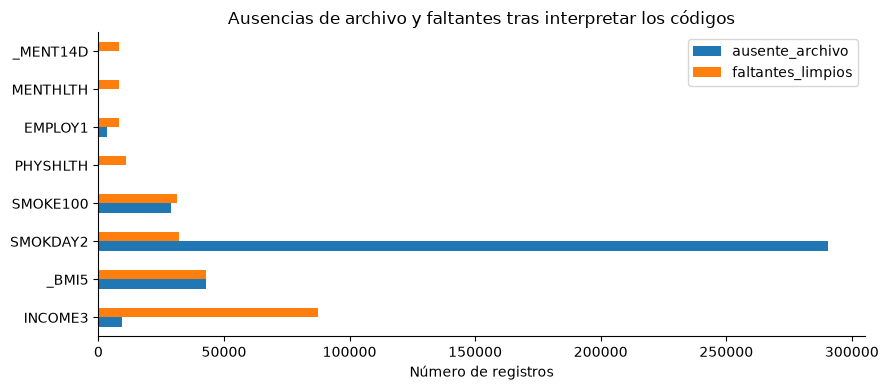

In [5]:
comparacion_faltantes = reporte[["ausente_archivo", "faltantes_limpios"]].sort_values("faltantes_limpios", ascending=False)
comparacion_faltantes.head(8).plot.barh()
plt.xlabel("Número de registros")
plt.ylabel("")
plt.title("Ausencias de archivo y faltantes tras interpretar los códigos")
plt.tight_layout()
plt.show()

### 2.3 Saltos en tabaquismo

`SMOKDAY2` se pregunta después de `SMOKE100`. Hay 258.956 registros con `SMOKE100 = 2` y la pregunta posterior vacía. Asigno a ese salto la categoría 0, que significa «no corresponde por no haber fumado 100 cigarrillos». No equivale a afirmar que la persona nunca fuma.

Cuando falta la respuesta anterior o aparece «no sabe» o «rechaza», el vacío posterior sigue siendo una ausencia. Las respuestas observadas 1, 2 y 3 mantienen su significado de frecuencia actual. Así se evita imputar todos los vacíos del cuestionario con la categoría más común.

In [6]:
pd.crosstab(crudo["SMOKE100"], crudo["SMOKDAY2"], dropna=False)

SMOKDAY2,1.0,2.0,3.0,7.0,9.0,NaN
SMOKE100,,,,,,
1.0,33118,13976,119598,194,190,166
2.0,0,0,0,0,0,258956
7.0,0,0,0,0,0,2062
9.0,0,0,0,0,0,550
NaN,0,0,0,0,0,28860


### 2.4 Construcción y comprobación del objetivo

Defino `malestar_frecuente = 1` para 14–30 días y 0 para 0–13; las respuestas desconocidas permanecen ausentes. El corte sigue la categoría publicada por CDC, pero la etiqueta sigue siendo una definición operativa del proyecto.

La comparación detecta cuatro diferencias entre `MENTHLTH` y las tres categorías de `_MENT14D`: dos respuestas de cero días aparecen en 1–13 días y otras dos de 2 o 3 días aparecen en cero. Las cuatro permanecen en el mismo lado del corte de 14 días. Registro la discrepancia, uso los días declarados para construir el objetivo y conservo los códigos originales; no corrijo la fuente silenciosamente.

In [7]:
discrepancias = pb.auditar_categorias_objetivo(limpio)
assert pb.validar_objetivo(limpio), "La definición binaria no coincide con la categoría CDC; revisar antes de continuar."
print("Discrepancias en las tres categorías:", len(discrepancias))
discrepancias

Discrepancias en las tres categorías: 4


,_STATE,SEQNO,MENTHLTH,_MENT14D,malestar_frecuente,categoria_desde_dias
93535,17,2024003628,3.0,1.0,0,2.0
93536,17,2024003629,0.0,2.0,0,1.0
93739,17,2024003832,0.0,2.0,0,1.0
93740,17,2024003833,2.0,1.0,0,2.0


In [8]:
distribucion = limpio[pb.OBJETIVO].value_counts(dropna=False).rename("registros").to_frame()
distribucion["porcentaje_total"] = 100 * distribucion.registros / len(limpio)
distribucion

,registros,porcentaje_total
malestar_frecuente,,
0,387199,84.602224
1,62315,13.615706
<NA>,8156,1.78207


## 3. Exploración de asociaciones (P2)

Se calculan asociaciones descriptivas sin ponderación sobre respuestas válidas por variable. Los denominadores varían y se muestran en las tablas. No se hacen pruebas de significación ni se interpretan estas asociaciones como efectos causales. La versión imputada aún no interviene en los cálculos.

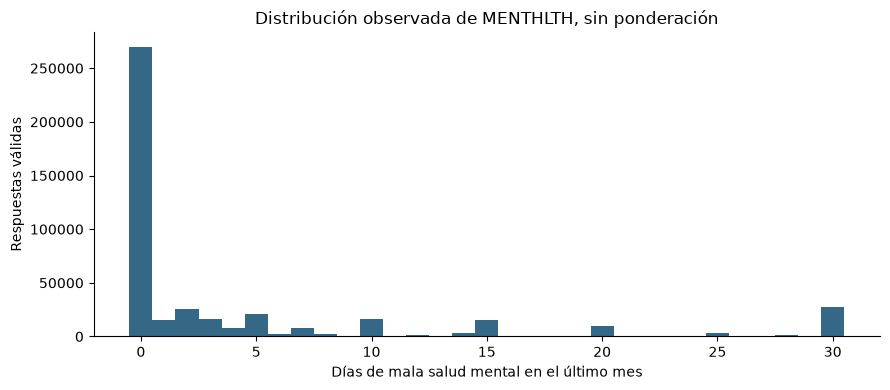

In [9]:
limpio["MENTHLTH"].dropna().plot.hist(bins=np.arange(-.5, 31.5, 1), color="#356786")
plt.xlabel("Días de mala salud mental en el último mes")
plt.ylabel("Respuestas válidas")
plt.title("Distribución observada de MENTHLTH, sin ponderación")
plt.tight_layout()
plt.show()

### 3.1 Comparación de variables numéricas

Para cada variable calculo `d = (media₁ − media₀) / s_combinada`, con `s_combinada² = ((n₁−1)s₁² + (n₀−1)s₀²) / (n₁+n₀−2)`. Las varianzas de cada grupo usan `ddof=1`. Ordeno por `|d|` y conservo el signo para interpretar la dirección.

Esta métrica compara diferencias en unidades de desviación estándar. No demuestra separación perfecta ni utilidad predictiva por sí sola. Edad es una variable topada e imputada por la fuente; días de salud física es un conteo acotado.

In [10]:
diferencias = pb.diferencias_estandarizadas(limpio)
diferencias

,variable,n_1,n_0,media_1,media_0,d,abs_d
2,PHYSHLTH,60871,380032,11.303215,3.493180,0.921834,0.921834
0,_AGE80,62315,387199,48.876466,56.032141,-0.398714,0.398714
1,_BMI5,57125,350849,29.730964,28.372056,0.206989,0.206989


La mayor diferencia estandarizada entre las tres variables corresponde a días de mala salud física (`d ≈ 0,922`). El grupo con malestar mental frecuente tiene menor edad media (`d ≈ −0,399`) y mayor IMC medio (`d ≈ 0,207`). Son comparaciones dentro de la muestra y no estimaciones del efecto de cambiar esas características.

### 3.2 Comparación de variables categóricas

Uso `V = sqrt(χ² / (n · min(r−1, c−1)))`, calculada sobre la tabla de contingencia de cada predictor y la etiqueta. `r` y `c` son sus números de categorías observadas; los valores esperados se obtienen a partir de los totales marginales. V se informa sin corrección por sesgo y no se mezcla en un mismo ranking con la diferencia estandarizada de medias.

In [11]:
asociaciones = pb.asociacion_categorica(limpio)
asociaciones

,variable,n_valido,v_cramer
2,ADDEPEV3,447268,0.376963
1,GENHLTH,448456,0.288418
6,EMPLOY1,441609,0.220333
4,MEDCOST1,448112,0.196458
7,INCOME3,365353,0.160917
8,MARITAL,445578,0.141155
10,SMOKDAY2,418456,0.127757
3,EXERANY2,448418,0.107535
5,EDUCA,447381,0.095536
9,SMOKE100,418954,0.088466


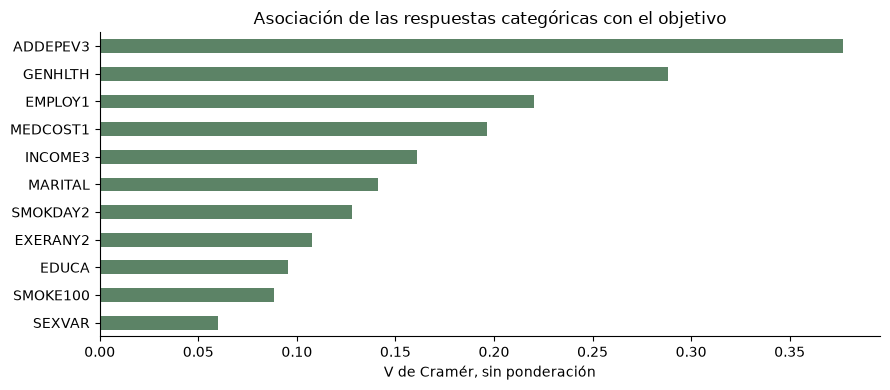

In [12]:
asociaciones.set_index("variable")["v_cramer"].sort_values().plot.barh(color="#5C8366")
plt.xlabel("V de Cramér, sin ponderación")
plt.ylabel("")
plt.title("Asociación de las respuestas categóricas con el objetivo")
plt.tight_layout()
plt.show()

El antecedente de trastorno depresivo autorreportado (`ADDEPEV3`, V ≈ 0,377), la salud general (`GENHLTH`, V ≈ 0,288) y la situación laboral (`EMPLOY1`, V ≈ 0,220) presentan las mayores asociaciones de este grupo. El antecedente depresivo y el resultado de salud mental son conceptos próximos, pero no equivalentes. Esta comparación no valida un diagnóstico ni establece una secuencia temporal.

## 4. Relación entre predictores (P3)

Calculo Spearman como la correlación de los rangos, con rango promedio para los empates y casos completos en cada par. El umbral `|ρ| ≥ 0,80` sirve para señalar asociaciones fuertes que revisar, sin eliminar columnas automáticamente. El análisis se limita a las tres variables numéricas; no declara independencia del resto del conjunto.

In [13]:
pares = pb.pares_correlacion(limpio, umbral=0.80)
pares

,variable_a,variable_b,rho,n_par,supera_umbral
0,_AGE80,_BMI5,-0.015317,414633,False
1,_AGE80,PHYSHLTH,0.033531,446603,False
2,_BMI5,PHYSHLTH,0.094639,405465,False


Ninguno de los tres pares supera el umbral; la mayor magnitud es aproximadamente 0,095. Eso no significa que todas las variables sean independientes. `SMOKE100` y `SMOKDAY2`, por ejemplo, están ligadas por un salto del cuestionario. En F3 se podrá evaluar si conservar ambas aporta algo al clasificador.

## 5. Preparación de la versión analítica

Conservo todas las filas en la versión limpia. Para el conjunto analítico, excluyo las 8.156 sin objetivo y dejo 449.514; no las borro del archivo de referencia.

En las tres variables numéricas imputo faltantes con la mediana y agrego indicadores de ausencia. Luego estandarizo con la media y la desviación poblacional (`ddof=0`) de la versión imputada. Es una elección exploratoria, no una afirmación de que sea la mejor preparación para cualquier modelo.

En las categóricas mantengo «Sin_respuesta» como categoría y aplico one-hot. Esto evita asumir distancias iguales entre tramos educativos o de ingreso. El salto de tabaquismo tiene su propia categoría. Las categorías admisibles se fijan desde el diccionario.

La clave, los ponderadores, el estrato y la unidad de muestreo se conservan como metadatos. `MENTHLTH` y `_MENT14D` se excluyen de los predictores porque permitirían reconstruir directamente el objetivo. El JSON registra la lista exacta de columnas predictoras; no debe usarse simplemente «todo salvo la etiqueta» para entrenar.

In [14]:
analitico, parametros = pb.construir_analitico(limpio)
x = analitico[parametros["predictores_salida"]]
print("Conjunto limpio:", limpio.shape)
print("Conjunto analítico:", analitico.shape)
print("Número de predictores codificados:", len(x.columns))
pd.DataFrame({"mediana_imputacion": parametros["medianas"], "centro": parametros["centros"], "escala": parametros["escalas"]})

Conjunto limpio: (457670, 22)
Conjunto analítico: (449514, 73)
Número de predictores codificados: 67


,mediana_imputacion,centro,escala
_AGE80,58.00,55.040168,18.116374
_BMI5,27.44,28.458617,6.278941
PHYSHLTH,0.00,4.483860,8.827027


Estos parámetros se ajustaron sobre los casos con etiqueta conocida de F2. Para evaluar un clasificador en F3 se volverá al conjunto limpio, se definirá la partición y se ajustará el preprocesador únicamente con entrenamiento. Los mismos parámetros se aplicarán a validación y prueba. También habrá que estudiar el desbalance de clases y el diseño muestral antes de interpretar los resultados.

## 6. Validación y pruebas

Los controles revisan la preservación de registros, la concordancia del objetivo binario y la ausencia de valores indefinidos entre los predictores preparados. Las cuatro discrepancias de categorías quedan en un reporte específico.

In [15]:
controles = {
    "filas_limpias_preservadas": len(limpio) == len(crudo),
    "filas_analiticas_justificadas": len(analitico) + int(limpio[pb.OBJETIVO].isna().sum()) == len(crudo),
    "objetivo_binario_coincide_cdc": pb.validar_objetivo(limpio),
    "predictores_finitos": bool(np.isfinite(x.to_numpy()).all()),
    "sin_fuga_directa_objetivo": not bool(set(x.columns) & {"MENTHLTH", "_MENT14D", pb.OBJETIVO}),
    "centros_cero": bool(np.allclose(x[pb.NUMERICAS].mean(), 0, atol=1e-9)),
    "desviaciones_uno": bool(np.allclose(x[pb.NUMERICAS].std(ddof=0), 1, atol=1e-9)),
}
with pb.RUTA_RAW.open("rb") as archivo:
    controles["crudo_no_modificado"] = hashlib.file_digest(archivo, "sha256").hexdigest() == fuente["sha256_seleccion"]
assert all(controles.values()), controles
pd.Series(controles, name="cumple").to_frame()

,cumple
filas_limpias_preservadas,True
filas_analiticas_justificadas,True
objetivo_binario_coincide_cdc,True
predictores_finitos,True
sin_fuga_directa_objetivo,True
centros_cero,True
desviaciones_uno,True
crudo_no_modificado,True


Las pruebas incluyen los límites de 13 y 14 días, códigos que cambian de significado según la variable, saltos del cuestionario y aplicación de medianas ya ajustadas a datos nuevos. Los casos artificiales se usan para comprobar el código; no se introducen en el archivo de encuesta.

In [16]:
pruebas = subprocess.run([sys.executable, "-m", "pytest", "tests/test_pipeline_brfss.py", "-q", "-p", "no:cacheprovider"], cwd=RAIZ, capture_output=True, text=True)
print(pruebas.stdout)
assert pruebas.returncode == 0, pruebas.stderr

.........................                                                [100%]
25 passed in 0.37s



## 7. Archivos resultantes

Los CSV grandes se guardan comprimidos y no se versionan. Los reportes pequeños y el JSON permiten revisar las decisiones y regenerar las salidas. La versión limpia conserva la información necesaria para preparar una evaluación posterior sin reutilizar el ajuste exploratorio.

In [17]:
pb.DIR_PROCESSED.mkdir(parents=True, exist_ok=True)
limpio.to_csv(pb.DIR_PROCESSED / "brfss_limpio.csv.gz", index=False)
analitico.to_csv(pb.DIR_PROCESSED / "brfss_analitico.csv.gz", index=False)
reporte.to_csv(RAIZ / "docs/reporte_calidad_f2.csv")
discrepancias.to_csv(RAIZ / "docs/discrepancias_objetivo.csv", index=False)
diferencias.to_csv(RAIZ / "docs/diferencias_numericas.csv", index=False)
asociaciones.to_csv(RAIZ / "docs/asociaciones_categoricas.csv", index=False)
pares.to_csv(RAIZ / "docs/correlaciones_numericas.csv", index=False)
parametros["sha256_seleccion_origen"] = fuente["sha256_seleccion"]
parametros["controles"] = controles
pb.guardar_json(parametros, pb.DIR_PROCESSED / "parametros_transformacion.json")
pd.DataFrame({"version": ["selección original", "limpia", "analítica exploratoria"],
              "filas": [len(crudo), len(limpio), len(analitico)],
              "columnas": [crudo.shape[1], limpio.shape[1], analitico.shape[1]]})

,version,filas,columnas
0,selección original,457670,21
1,limpia,457670,22
2,analítica exploratoria,449514,73


## 8. Conclusiones y trabajo pendiente

**P1.** La clave compuesta es única. La limpieza distingue no respuesta de códigos válidos y saltos: se identifican 258.956 saltos de tabaquismo y 87.423 faltantes interpretados de ingreso. Se documentan cuatro discrepancias entre días de mala salud mental y la clasificación de tres niveles, sin discrepancias en el corte binario.

**P2.** Entre las numéricas, los días de mala salud física presentan la mayor diferencia estandarizada. Entre las categóricas, el antecedente depresivo autorreportado tiene la mayor V de Cramér. Las métricas y sus denominadores permiten repetir estas comparaciones; aún no se ha evaluado capacidad predictiva.

**P3.** Las tres asociaciones numéricas no superan el umbral de revisión. Las dependencias conocidas del cuestionario se conservan documentadas y no se presentan como hallazgos nuevos.

La preparación entrega 449.514 casos con etiqueta y 67 predictores codificados, además de identificadores y variables del diseño. Los 8.156 casos sin objetivo siguen en la versión limpia. F3 deberá diseñar las mediciones de rendimiento y la evaluación del clasificador, reajustando toda transformación que dependa de los datos dentro de entrenamiento. Las cifras de este notebook describen la muestra sin ponderación.

### Referencias

- CDC. (2025). [BRFSS 2024: datos y documentación](https://www.cdc.gov/brfss/annual_data/annual_2024.html).
- CDC. (2025). [Diccionario de códigos BRFSS 2024](https://www.cdc.gov/brfss/annual_data/2024/zip/codebook24_llcp-v2-508.zip).
- CDC. (2025). [Variables calculadas: definición de `_MENT14D`](https://www.cdc.gov/brfss/annual_data/2024/pdf/2024-calculated-variables-version4-508.pdf).